# Using and validating the derivative classes

`StableEMRIFisher` computes waveform derivatives with a derivative class: `StableDerivative` for `deriv_type='stable'` and `DirectDerivative` for `deriv_type='direct'`. This example uses both classes directly, without building a Fisher matrix, and checks the stable derivative of the waveform with respect to the initial eccentricity `e0`:

- **Part 1, without the response:** compares stencils of different order and kind, compares with direct finite differences of the full waveform, and shows how both depend on the step size.
- **Part 2, with the LISA response:** the same comparisons for the A and E TDI channels.

To check how well a Fisher matrix describes the likelihood, see `stable_derivative_one_param_no_response.ipynb` and `stable_derivative_one_param_with_response.ipynb`.

**Requirements:** Part 1 only needs FEW and StableEMRIFisher. Part 2 also needs `lisaanalysistools` and `fastlisaresponse` (see the installation guide).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import few
from few.waveform import FastSchwarzschildEccentricFlux
from fastlisaresponse import ResponseWrapper
from lisatools.detector import EqualArmlengthOrbits
from lisatools.sensitivity import get_sensitivity, A1TDISens, E1TDISens

from stableemrifisher.derivatives import StableDerivative, DirectDerivative

use_gpu = False  # set to True to run on an NVIDIA GPU

if not use_gpu:
    # restrict FEW to its CPU backend
    cfg_set = few.get_config_setter(reset=True)
    cfg_set.enable_backends("cpu")


def to_numpy(array):
    """Copy an array to the CPU, for plotting."""
    return array.get() if use_gpu else array


def max_relative_difference(a, b):
    """Largest difference between two derivatives, relative to the largest value of b."""
    return float(abs(a - b).max() / abs(b).max())

## Source and settings

Both derivative classes take a FEW waveform class and the keyword arguments of FEW's waveform generator, build the waveform model themselves, and return derivatives in the same layout as SEF's waveforms: one row per channel. `set_reference` sets the point at which derivatives are computed: the source parameters and the waveform settings `T` and `dt`.

In [2]:
T = 0.01  # observation time, years (short, to keep the notebook fast)
dt = 10.0  # sampling interval, seconds

wave_params = dict(
    m1=1e6,  # primary mass, solar masses
    m2=10.0,  # secondary mass, solar masses
    a=0.0,  # primary spin
    p0=9.5,  # initial semi-latus rectum
    e0=0.4,  # initial eccentricity
    xI0=1.0,  # cosine of the initial inclination
    dist=1.0,  # luminosity distance, Gpc
    qS=np.pi / 3,  # sky location, polar angle
    phiS=np.pi / 4,  # sky location, azimuthal angle
    qK=np.pi / 6,  # spin orientation, polar angle
    phiK=np.pi / 8,  # spin orientation, azimuthal angle
    Phi_phi0=1.0,  # initial azimuthal phase
    Phi_theta0=0.0,  # initial polar phase
    Phi_r0=0.0,  # initial radial phase
)

param = "e0"
delta = 1e-5  # finite-difference step

waveform_generator_kwargs = dict(
    mode_selector_kwargs=dict(mode_selection_threshold=1e-5),
    inspiral_kwargs=dict(err=1e-11, max_iter=10000),  # trajectory integrator settings
)

# plot the first 6 hours of a channel
n_show = int(6 * 3600 / dt)
time_hours = np.arange(n_show) * dt / 3600

## Part 1: without the response

Without a response, the derivatives have two rows, $[\partial h_+, \partial h_\times]$.

### The stable derivative

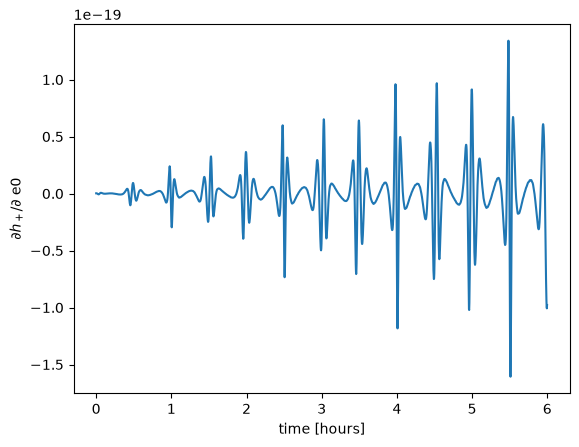

In [3]:
stable = StableDerivative(
    waveform_class=FastSchwarzschildEccentricFlux,
    waveform_generator_kwargs=waveform_generator_kwargs,
    use_gpu=use_gpu,
)
stable.set_reference(wave_params, T=T, dt=dt)

der = stable(param, delta, order=4, kind="central")

plt.plot(time_hours, to_numpy(der[0, :n_show]))
plt.xlabel("time [hours]")
plt.ylabel(rf"$\partial h_+ / \partial$ {param}")
plt.show()

### Different stencils

The same derivative with a 2nd-order backward stencil instead of the 4th-order central one.

In [4]:
der_2nd = stable(param, delta, order=2, kind="backward")

print(f"max relative difference: {max_relative_difference(der_2nd, der):.1e}")

max relative difference: 4.3e-07


### Direct finite differences

`DirectDerivative` differentiates the full waveform by finite differences. For a like-for-like comparison, it keeps exactly the modes the stable derivative selected for the reference waveform (`stable.engine.cache["mode_selection"]`).

max relative difference: 4.6e-05


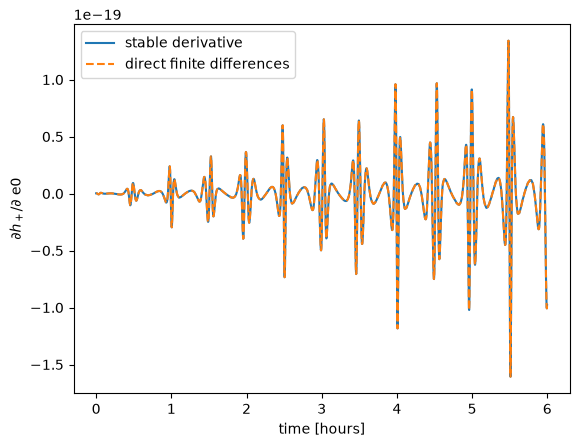

In [5]:
same_modes = dict(
    waveform_generator_kwargs,
    mode_selector_kwargs=dict(mode_selection=stable.engine.cache["mode_selection"]),
)

direct = DirectDerivative(
    waveform_class=FastSchwarzschildEccentricFlux,
    waveform_generator_kwargs=same_modes,
    use_gpu=use_gpu,
)
direct.set_reference(wave_params, T=T, dt=dt)

der_direct = direct(param, delta, order=4, kind="central")

print(f"max relative difference: {max_relative_difference(der_direct, der):.1e}")

plt.plot(time_hours, to_numpy(der[0, :n_show]), label="stable derivative")
plt.plot(time_hours, to_numpy(der_direct[0, :n_show]), "--", label="direct finite differences")
plt.xlabel("time [hours]")
plt.ylabel(rf"$\partial h_+ / \partial$ {param}")
plt.legend()
plt.show()

### Dependence on the step size

Repeat both derivatives for a range of step sizes, and compare each with the stable derivative at `delta` above. The stable derivative differentiates the trajectory and the mode amplitudes rather than the waveform, so it barely changes with the step size. Direct finite differences of the full waveform only agree with it in a narrow range of steps: larger steps suffer from truncation error, smaller ones from numerical noise. This is why SEF searches for a stable step size, and why the stable derivative makes that search robust.

In [6]:
print(f"{'step':>8s}  {'stable':>8s}  {'direct':>8s}")
for step in [1e-3, 1e-4, 1e-5, 1e-6, 1e-7]:
    stable_err = max_relative_difference(stable(param, step, order=4, kind="central"), der)
    direct_err = max_relative_difference(direct(param, step, order=4, kind="central"), der)
    print(f"{step:8.0e}  {stable_err:8.1e}  {direct_err:8.1e}")

    step    stable    direct
   1e-03   9.9e-06   1.0e+00
   1e-04   2.2e-06   4.3e-02
   1e-05   0.0e+00   4.6e-05
   1e-06   1.1e-06   6.2e-04
   1e-07   3.2e-05   3.3e-03


## Part 2: with the LISA response

The same comparisons for the waveform as seen by LISA: first-generation TDI on equal-arm-length orbits, A and E channels. With a response, `StableDerivative` applies the response to the derivative of $h$ (for the sky angles, which the response also depends on, it differentiates the response-wrapped waveform by finite differences instead), while `DirectDerivative` differentiates the response-wrapped waveform $R[h]$. The derivatives have one row per TDI channel. The first and last `t0` seconds of the signal are set to zero by the response, so the plot starts after them.

different stencils:         max relative difference 4.4e-07
direct finite differences:  max relative difference 4.9e-05


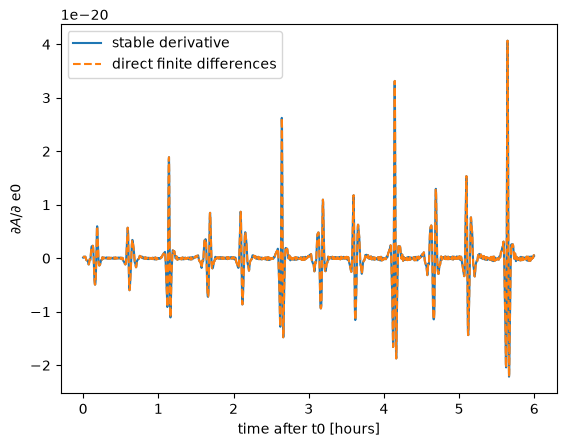

In [7]:
ResponseWrapper_kwargs = dict(
    Tobs=T,
    dt=dt,
    index_lambda=8,  # position of phiS in the waveform arguments
    index_beta=7,  # position of qS in the waveform arguments
    t0=10000.0,  # seconds at each end of the signal where the response is unreliable
    remove_garbage="zero",  # zero the signal within t0 of each end
    flip_hx=True,  # FEW returns h+ - i hx
    is_ecliptic_latitude=False,  # qS is a polar angle, not a latitude
    orbits=EqualArmlengthOrbits(),
    order=20,  # order of the Lagrange interpolation of the time delays
    tdi="1st generation",
    tdi_chan="AE",
)

stable_response = StableDerivative(
    waveform_class=FastSchwarzschildEccentricFlux,
    waveform_generator_kwargs=waveform_generator_kwargs,
    ResponseWrapper=ResponseWrapper,
    ResponseWrapper_kwargs=ResponseWrapper_kwargs,
    use_gpu=use_gpu,
)
stable_response.set_reference(wave_params, T=T, dt=dt)
der_response = stable_response(param, delta, order=4, kind="central")

direct_response = DirectDerivative(
    waveform_class=FastSchwarzschildEccentricFlux,
    waveform_generator_kwargs=same_modes,
    ResponseWrapper=ResponseWrapper,
    ResponseWrapper_kwargs=ResponseWrapper_kwargs,
    use_gpu=use_gpu,
)
direct_response.set_reference(wave_params, T=T, dt=dt)
der_direct_response = direct_response(param, delta, order=4, kind="central")

der_response_2nd = stable_response(param, delta, order=2, kind="backward")

print(f"different stencils:         max relative difference {max_relative_difference(der_response_2nd, der_response):.1e}")
print(f"direct finite differences:  max relative difference {max_relative_difference(der_direct_response, der_response):.1e}")

# plot 6 hours of the A channel, starting after the first t0 seconds
start = int(ResponseWrapper_kwargs["t0"] / dt)
plt.plot(time_hours, to_numpy(der_response[0, start:start + n_show]), label="stable derivative")
plt.plot(time_hours, to_numpy(der_direct_response[0, start:start + n_show]), "--", label="direct finite differences")
plt.xlabel("time after t0 [hours]")
plt.ylabel(rf"$\partial A / \partial$ {param}")
plt.legend()
plt.show()

## What this shows

With and without the LISA response, the stable derivative of the waveform with respect to `e0` does not depend on the finite-difference stencil, agrees with direct finite differences of the full waveform where those are accurate, and is far less sensitive to the step size.